<h1>TP1 Deep Learning</h1>

Ce premier TP est dédié à la prise en main de l'environnement de travail : python, notebook, keras/tensorflow... Cette séance vous permettra de manipuler un premier jeu de données, de mettre en oeuvre des premiers réseaux de neurones et les comparer à d'autres méthodes de classification (via sklearn).

<h2> Configuration </h2>

Une fois créé l'environnement virtuel <i>deep</i>, nous devons dans un premier temps configurer le notebook pour utiliser les packages installés :

Import des premiers packages nécessaires :

In [2]:
import numpy as np
import tensorflow

print(tensorflow.version.VERSION)
keras = tensorflow.keras
from keras.models import Sequential
from keras.datasets import mnist
from keras.utils import to_categorical


2.21.0


<h2> Chargement des données</h2>

Ici on charge le jeu de données MNIST (les chiffres manuscrits), puis quelques instructions de mise en forme

In [3]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()
print(x_train.shape)
print(x_test.shape)
img_rows, img_cols = 28, 28
num_classes = 10
nb_samples = len(x_train)
#x_train = x_train.reshape(x_train.shape[0], img_rows, img_cols, 1)
x_train = x_train.reshape(x_train.shape[0], img_rows * img_cols)
#x_test = x_test.reshape(x_test.shape[0], img_rows, img_cols, 1)
x_test = x_test.reshape(x_test.shape[0], img_rows * img_cols)
input_shape = x_train[0].shape
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255
x_test /= 255

(60000, 28, 28)
(10000, 28, 28)


Le jeu de données MNIST contient 60000 exemples répartis en 10 classes. Nous allons ici en sélectionner aléatoirement un certain nombre pour accélérer les étapes suivantes.

In [4]:
l_idx = list(range(nb_samples))
np.random.shuffle(l_idx)
l_idx = l_idx[:10000]

x_train, y_train = x_train[l_idx], y_train[l_idx]

<h2> Essais de divers classifieurs </h2>

Utilisons la bibliothèque <i>scikit-learn</i> pour tester plusieurs classifeurs qui nous serviront de références

In [5]:
from sklearn import svm, linear_model
import pandas as pd

In [6]:
models = [("Ridge", linear_model.RidgeClassifier()), ("Logistic Regression", linear_model.LogisticRegression()), ("Perceptron", linear_model.Perceptron(max_iter=40)), ("SVM", svm.SVC(kernel='rbf', verbose=1, max_iter=50))]
results = []

for name, clf in models:
    clf.fit(x_train.reshape((-1, img_rows * img_cols)), y_train)
    results.append([name, clf.score(x_test.reshape((-1, img_rows * img_cols)), y_test)])

df = pd.DataFrame(results, columns = ["Model", "Accuracy"])
print(df)

c:\Users\felip\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


[LibSVM]

c:\Users\felip\anaconda3\Lib\site-packages\sklearn\svm\_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=50).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


                 Model  Accuracy
0                Ridge    0.8498
1  Logistic Regression    0.9074
2           Perceptron    0.8524
3                  SVM    0.9222


<b>A FAIRE:</b> Comparez plusieurs modèles et affichez un tableau récapitulatif des performances obtenues

Ridge : 0.8498

LR : 0.9074

Perceptron : 0.8524

SVM : 0.9222

<h2> Réseaux de neurones </h2>

Utilisons maintenant <i>keras</i> pour instancier et évaluer des réseaux de neurones

Il est d'abord nécessaire de formater les vecteurs d'étiquettes en <i>one-hot vectors</i> de tailles num_classes. Ces vecteurs contiennent des 0 et un seul 1 par ligne à l'indice correspondant à la classe

In [29]:

print(y_train[:3])

y_train = to_categorical(y_train, num_classes)
y_test = to_categorical(y_test, num_classes)

print(y_train.shape)

print(y_train[:3])

[8 2 7]
(10000, 10)
[[0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]]


In [6]:
from keras.layers import Dense, Flatten
from keras.optimizers import SGD, Adam

sgd = Adam(learning_rate=0.01)

Commençons par un réseau très simple (un perceptron multiclasses), équivalent à une régression logistique.

In [31]:
model = Sequential()
model.add(Flatten(input_shape=input_shape))
model.add(Dense(num_classes, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

print(model.summary())

c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_8 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         7,850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,850 (30.66 KB)

 Trainable params: 7,850 (30.66 KB)

 Non-trainable params: 0 (0.00 B)

None


In [32]:
model = Sequential()
model.add(Flatten(input_shape=input_shape))
model.add(Dense(512, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))
model.compile(loss='categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

print(model.summary())

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_9 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,050 (1.55 MB)

 Trainable params: 407,050 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

None


La fonction model.summary() affiche un tableau résumant l'architecture du réseau.

<b>A FAIRE :</b> Décrivez à quoi correspondent les valeurs affichées, modifiez l'architecture et expliquez les nouvelles valeurs.

Layer (type) : type de couche utilisée.

Output Shape : nombre de données en sortie de chaque couche.

Param # : nombre de paramètres entraînables par couche.

Total params: nombre total de paramètres du réseau.

Trainable params : paramètres ajustés pendant l'entraînement.

Non-trainable params : paramètres qui n'ont été ajustés pendant l'entraînement.

Considérant que N est le nombre de neurones dans la couche précédente et M est le nombre de neurones dans la couche actuelle, le nombre de paramètres dans une couche dense est params = N x M + M. On additionne M dans la formule parce que chaque neurone de la couche actuelle a un biais, car la formule d'un neurone est z = w0 + w1 + x1 + ... + wn + xn, où w0 est le bias. Alors, si après une couche flatten de taille 784 on ajoute une couche dense de taille 512, on aura 784 x 512 + 512 = 401920, qui est plus grand que 7850. Avec cette couche, on peut faire un entraînement plus efficace. On doit juste éviter de faire un overfitting, qui est quand on entraîne beaucoup un modèle.

<h3> Entrainement du réseau </h3>

Dans cette partie, nous considérons un réseau extrèmenent simple, sans couche cachée. Pour entrainer le réseau, on peut utiliser la fonction <i>fit</i> qui s'utilise comme dans <i>scikit-learn</i>. La fonction <i>evaluate</i> est l'équivalent de la fonction <i>score</i>.

In [11]:
from sklearn.model_selection import KFold

k = 3
accs = []

for lr in [0.1, 0.01]:
  print("START TRAINING WITH LR =", lr)
  kf = KFold(n_splits=k, shuffle=True, random_state=42)
  acc = []

  for train_idx, val_idx in kf.split(x_train):
    sgd = SGD(learning_rate=lr)
    model = Sequential()
    model.add(Flatten(input_shape=input_shape))
    #model.add(Dense(512, activation='relu'))
    model.add(Dense(num_classes, activation='softmax'))
    model.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

    loss = model.fit(x_train[train_idx], y_train[train_idx], batch_size=2048, epochs=1000, validation_data=(x_train[val_idx], y_train[val_idx]), verbose=1)
    score = model.evaluate(x_train[val_idx], y_train[val_idx], verbose=1)
    acc.append(score[1])
    
    print("score=", score)

  accs.append([lr, np.mean(acc)])

best_lr, best_acc = accs[0]

for lr, acc in accs:
  print(f"Mean accuracy for learning rate = {lr} : {acc}")
  if acc > best_acc:
    best_lr = lr
    best_acc = acc

print (f"Highest accuracy :\nlr = {best_lr}\nAccuracy : {best_acc}")



START TRAINING WITH LR = 0.1
Epoch 1/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 79ms/step - accuracy: 0.1128 - loss: 2.3388 - val_accuracy: 0.3683 - val_loss: 2.0387
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.4380 - loss: 1.9508 - val_accuracy: 0.6026 - val_loss: 1.7419
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6313 - loss: 1.6750 - val_accuracy: 0.6986 - val_loss: 1.5187
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7072 - loss: 1.4704 - val_accuracy: 0.7277 - val_loss: 1.3564
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7448 - loss: 1.3164 - val_accuracy: 0.7639 - val_loss: 1.2280
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7678 - loss: 1.1983 - val_accuracy: 0.7819 - val_loss: 1.1296
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7805 - loss: 1.1066 - val_accuracy: 0.7975 - val_loss: 1.0485
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7942 - loss: 1.03

Le choix et la configuration de la procédure d'optimisation est cruciale. SGD est particulièrement sensible à ses paramètres (<i>learning rate</i>, <i>momentum</i>). Nous restons ici sur notre perceptron multiclasses.

<b>A FAIRE :</b> Utilisez la validation croisée pour déterminer le meilleur jeu de paramètres de SGD pour ce réseau ; comparez les résultats obtenus.

En testant différents learning rates (0.1 et 0.01) à l’aide de la validation croisée, on peut conclure que la meilleure valeur testée est 0.1, car elle présente la précision la plus élevée (0.9060993989308676).

Mean accuracy for learning rate = 0.1 : 0.9060993989308676

Mean accuracy for learning rate = 0.01 : 0.883899470170339

Highest accuracy : lr = 0.1; Accuracy : 0.9060993989308676

Pour tester différents types d’hyperparamètres de natures distinctes, on peut utiliser plusieurs boucles, comme dans le code suivant. Cette approche fonctionne comme un Grid Search, qui consiste à tester différentes combinaisons d’hyperparamètres afin de déterminer celle qui donne la meilleure précision. Le meilleur résultat a été obtenu encore avec un momentum de 0.0 et un learning rate de 0.1, affichant une précision de 0.9058995842933655.

Mean accuracy for momentum = 0.0 and learning rate = 0.1 : 0.9058995842933655

Mean accuracy for momentum = 0.0 and learning rate = 0.01 : 0.8816992044448853

Mean accuracy for momentum = 0.1 and learning rate = 0.1 : 0.9051994681358337

Mean accuracy for momentum = 0.1 and learning rate = 0.01 : 0.8858991463979086

Highest accuracy : Momentum = 0.0; lr = 0.1; Accuracy : 0.9058995842933655

In [12]:
from sklearn.model_selection import KFold

k = 3
accs = []

for m in [0.0, 0.1]:
  print("START TRAINING WITH MOMENTUM =", m)
  for lr in [0.1, 0.01]:
    print("START TRAINING WITH LR =", lr)
    kf = KFold(n_splits=k, shuffle=True, random_state=42)
    acc = []

    for train_idx, val_idx in kf.split(x_train):
      sgd = SGD(learning_rate=lr, momentum=m)
      model = Sequential()
      model.add(Flatten(input_shape=input_shape))
      #model.add(Dense(512, activation='relu'))
      model.add(Dense(num_classes, activation='softmax'))
      model.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

      loss = model.fit(x_train[train_idx], y_train[train_idx], batch_size=2048, epochs=1000, validation_data=(x_train[val_idx], y_train[val_idx]), verbose=1)
      score = model.evaluate(x_train[val_idx], y_train[val_idx], verbose=1)
      acc.append(score[1])
      
      print("score=", score)

    accs.append([m, lr, np.mean(acc)])

best_m, best_lr, best_acc = accs[0]

for m, lr, acc in accs:
  print(f"Mean accuracy for momentum = {m} and learning rate = {lr} : {acc}")
  if acc > best_acc:
    best_m = m
    best_lr = lr
    best_acc = acc

print (f"Highest accuracy :\nMomentum = {best_m}\nlr = {best_lr}\nAccuracy : {best_acc}")



START TRAINING WITH MOMENTUM = 0.0
START TRAINING WITH LR = 0.1
Epoch 1/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 75ms/step - accuracy: 0.1970 - loss: 2.2598 - val_accuracy: 0.3980 - val_loss: 1.9754
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4880 - loss: 1.8803 - val_accuracy: 0.6053 - val_loss: 1.6968
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.6403 - loss: 1.6254 - val_accuracy: 0.6746 - val_loss: 1.4856
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.7019 - loss: 1.4347 - val_accuracy: 0.7160 - val_loss: 1.3288
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.7406 - loss: 1.2904 - val_accuracy: 0.7525 - val_loss: 1.2091
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.7670 - loss: 1.1793 - val_accuracy: 0.7681 - val_loss: 1.1163
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.7787 - loss: 1.0915 - val_accuracy: 0.7846 - val_loss: 1.0413
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/s

<h3>Etude du déroulement de l'entrainement</h3>

Le code ci-dessous trace les courbes d'évolution de la loss et de l'accuracy obtenues sur l'ensemble d'apprentissage et sur un ensemble de validation.

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


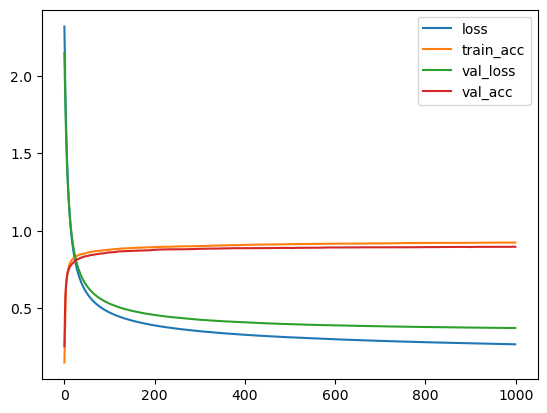

In [23]:
import matplotlib.pyplot as plt
#%matplotlib notebook
%matplotlib inline

print(loss.history.keys())

plt.plot(loss.history['loss'], label="loss")
plt.plot(loss.history['accuracy'], label="train_acc")
plt.plot(loss.history['val_loss'], label="val_loss")
plt.plot(loss.history['val_accuracy'], label="val_acc")
plt.legend()
plt.show()

<h3> Identifier le surapprentissage </h3>

Lorsque la courbe "loss" décroit mais que "val_loss" ne suit pas, c'est que le réseau surapprend (overfitting). Plusieurs techniques de régularisation permettent d'éviter ces situations (à voir en cours) : augmenter la taille du minibatch peut éviter l'overfitting tout en accélerant l'apprentissage, mais au dépend d'une réduction de la précision lorsque le minibatch est trop grand. A noter aussi qu'il faut aussi un espace mémoire (RAM ou GPU) suffisant pour charger le minibatch en plus des paramètres du réseau.

<b>A FAIRE : </b> Augmentez le minibatch et commentez les courbes obtenues. Attention, si vous appelez la fonction <i>fit</i> sans réinstancier le modèle (la cellule d'avant..), l'entrainement continue où il en était et faussera vos conclusions.

R : Avec un minibatch de 4096, la courbe val_acc commence plus près de 0.5 et les courbes loss et val_loss se rapprochent des valeurs plus faibles qu'avec un minibatch de 2048, suggérant une meilleure évolution de l'apprentissage quand on utilise un minibatch de 4096.

### batch_size=2048

In [24]:
from sklearn.model_selection import KFold

k = 3
accs = []

lr = 0.1

print("START TRAINING WITH LR =", lr)
kf = KFold(n_splits=k, shuffle=True, random_state=42)
acc = []

for train_idx, val_idx in kf.split(x_train):
  sgd = SGD(learning_rate=lr)
  model = Sequential()
  model.add(Flatten(input_shape=input_shape))
  #model.add(Dense(512, activation='relu'))
  model.add(Dense(num_classes, activation='softmax'))
  model.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

  loss = model.fit(x_train[train_idx], y_train[train_idx], batch_size=2048, epochs=1000, validation_data=(x_train[val_idx], y_train[val_idx]), verbose=1)
  score = model.evaluate(x_train[val_idx], y_train[val_idx], verbose=1)
  acc.append(score[1])
  
  print("score=", score)

accs.append([lr, np.mean(acc)])

best_lr, best_acc = accs[0]

for lr, acc in accs:
  print(f"Mean accuracy for learning rate = {lr} : {acc}")
  if acc > best_acc:
    best_lr = lr
    best_acc = acc

print (f"Highest accuracy :\nlr = {best_lr}\nAccuracy : {best_acc}")



START TRAINING WITH LR = 0.1
Epoch 1/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 106ms/step - accuracy: 0.1871 - loss: 2.2288 - val_accuracy: 0.4100 - val_loss: 1.9578
Epoch 2/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.4835 - loss: 1.8739 - val_accuracy: 0.5777 - val_loss: 1.6868
Epoch 3/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6137 - loss: 1.6251 - val_accuracy: 0.6674 - val_loss: 1.4834
Epoch 4/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.6866 - loss: 1.4374 - val_accuracy: 0.7175 - val_loss: 1.3300
Epoch 5/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7225 - loss: 1.2961 - val_accuracy: 0.7466 - val_loss: 1.2160
Epoch 6/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7483 - loss: 1.1875 - val_accuracy: 0.7744 - val_loss: 1.1228
Epoch 7/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7754 - loss: 1.1016 - val_accuracy: 0.7762 - val_loss: 1.0547
Epoch 8/1000
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7808 - loss: 1.0

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


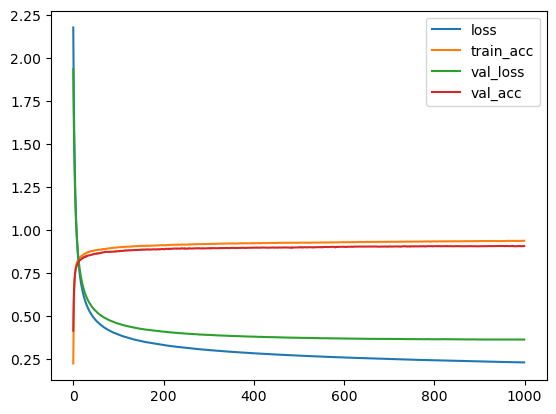

In [26]:
import matplotlib.pyplot as plt
#%matplotlib notebook
%matplotlib inline

print(loss.history.keys())

plt.plot(loss.history['loss'], label="loss")
plt.plot(loss.history['accuracy'], label="train_acc")
plt.plot(loss.history['val_loss'], label="val_loss")
plt.plot(loss.history['val_accuracy'], label="val_acc")
plt.legend()
plt.show()

### batch_size=4096

In [21]:
from sklearn.model_selection import KFold

k = 3
accs = []

lr = 0.1

print("START TRAINING WITH LR =", lr)
kf = KFold(n_splits=k, shuffle=True, random_state=42)
acc = []

for train_idx, val_idx in kf.split(x_train):
  sgd = SGD(learning_rate=lr)
  model = Sequential()
  model.add(Flatten(input_shape=input_shape))
  #model.add(Dense(512, activation='relu'))
  model.add(Dense(num_classes, activation='softmax'))
  model.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

  loss = model.fit(x_train[train_idx], y_train[train_idx], batch_size=4096, epochs=1000, validation_data=(x_train[val_idx], y_train[val_idx]), verbose=1)
  score = model.evaluate(x_train[val_idx], y_train[val_idx], verbose=1)
  acc.append(score[1])
  
  print("score=", score)

accs.append([lr, np.mean(acc)])

best_lr, best_acc = accs[0]

for lr, acc in accs:
  print(f"Mean accuracy for learning rate = {lr} : {acc}")
  if acc > best_acc:
    best_lr = lr
    best_acc = acc

print (f"Highest accuracy :\nlr = {best_lr}\nAccuracy : {best_acc}")



START TRAINING WITH LR = 0.1


c:\Users\felip\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 242ms/step - accuracy: 0.1391 - loss: 2.2936 - val_accuracy: 0.2915 - val_loss: 2.1153
Epoch 2/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.3114 - loss: 2.0828 - val_accuracy: 0.4451 - val_loss: 1.9438
Epoch 3/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.4524 - loss: 1.9177 - val_accuracy: 0.5531 - val_loss: 1.7971
Epoch 4/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.5603 - loss: 1.7765 - val_accuracy: 0.6326 - val_loss: 1.6716
Epoch 5/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.6344 - loss: 1.6539 - val_accuracy: 0.6878 - val_loss: 1.5627
Epoch 6/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6841 - loss: 1.5481 - val_accuracy: 0.7148 - val_loss: 1.4692
Epoch 7/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7105 - loss: 1.4565 - val_accuracy: 0.7379 - val_loss: 1.3873
Epoch 8/1000
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7288 - loss: 1.3770 - val_accuracy: 0.7463 - 

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


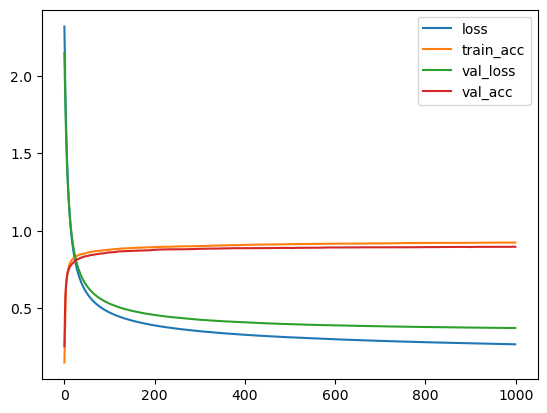

In [22]:
import matplotlib.pyplot as plt
#%matplotlib notebook
%matplotlib inline

print(loss.history.keys())

plt.plot(loss.history['loss'], label="loss")
plt.plot(loss.history['accuracy'], label="train_acc")
plt.plot(loss.history['val_loss'], label="val_loss")
plt.plot(loss.history['val_accuracy'], label="val_acc")
plt.legend()
plt.show()

<h3> Identifier la convergence </h3>

Lorsque les courbes "loss" (et/ou "val_loss") ne décroient plus significativement, c'est que l'entrainement arrive à convergence. Au delà (ie: continuer des epochs), les performances peuvent se déteriorer (surapprentissage, divergence de l'optimisation, ...). La problématique de s'arrêter au bon moment est connue sous le nom d'arrêt précoce (ou plutôt "early stopping"). Keras offre un tel mécanisme, via un callback dédié...

Dans la cellule suivante, l'entrainement s'arrêtera lorsque "val_loss" a une différence inférieure à 0.005 entre 2 epochs.

In [27]:
from keras.callbacks import EarlyStopping

es = EarlyStopping(monitor='val_loss', min_delta=0.005, patience=2, verbose=1, mode='auto')
loss = model.fit(x_train, y_train, batch_size=128, epochs=100, validation_split=0.8, callbacks=[es], verbose=0)

score = model.evaluate(x_test, y_test, verbose=0)
print("score=", score)

Epoch 3: early stopping
score= [0.30975285172462463, 0.9108999967575073]


<h3> Réseau plus "profond" </h3>

Le réseau considéré jusque là n'avait aucune couche cachée, nous allons à présent ajouter des couches intermédiaires. Pour faciliter l'entrainement du réseau lorsqu'il devient profond, nous pouvons intercaler des couches "BatchNormalization" et/ou "Dropout" (à discuter en cours).

In [29]:
from keras.layers import Dropout, BatchNormalization

sgd = SGD(learning_rate=0.1)

model2 = Sequential()
model2.add(Flatten(input_shape=input_shape))
model2.add(Dense(512, activation='relu', kernel_regularizer=keras.regularizers.l2(l2=0.001)))
model2.add(Dropout(0.2))
model2.add(BatchNormalization())
model2.add(Dense(512, activation='relu', kernel_regularizer=keras.regularizers.l2(l2=0.001)))
model2.add(Dropout(0.2))
model2.add(BatchNormalization())
model2.add(Dense(num_classes, activation='softmax'))
model2.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

print(model2.summary())

loss = model2.fit(x_train, y_train, batch_size=128, epochs=100, validation_split=0.9, callbacks=[], verbose=1)

score = model2.evaluate(x_test, y_test, verbose=0)
print("score=", score)

Model: "sequential_39"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_39 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,802 (2.57 MB)

 Trainable params: 671,754 (2.56 MB)

 Non-trainable params: 2,048 (8.00 KB)

None
Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.5956 - loss: 2.4269 - val_accuracy: 0.5389 - val_loss: 2.8355
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8769 - loss: 1.5468 - val_accuracy: 0.6459 - val_loss: 2.6885
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9179 - loss: 1.4017 - val_accuracy: 0.6390 - val_loss: 2.6030
Epoch 4/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.9469 - loss: 1.3149 - val_accuracy: 0.6764 - val_loss: 2.5195
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.9630 - loss: 1.2632 - val_accuracy: 0.7220 - val_loss: 2.4350
Epoch 6/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.9800 - loss: 1.2197 - val_accuracy: 0.7298 - val_loss: 2.3735
Epoch 7/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - accuracy: 0.9880 - loss: 1.1888 - val_accuracy: 0.7578 - val_loss: 2.3073
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.9940 - loss: 1.1719 - val_accuracy: 0.7644 - val_

La performance d'un réseau de neurones dépend énormément de son architecture (nombre de neurones, nombre de couches, non-linéarités).

<b>A FAIRE : </b> Modifiez ce que vous pouvez (raisonnablement) et utilisez le principe de validation croisée pour déterminer une bonne architecture . Vous pourriez faire varier le nombre de neurones par couche,

R : J'ai changé le nombre de neurones dans les couches denses et leur fonction d'activation. J'ai essayé avec les hyperparamètres suivants :

Nombre de neurones dans les couches denses = 512 et 1024

Fonction d'activation = relu et elu

Le meilleur résultat obtenu était quand on a utilisé 512 neurones dans les couches denses et la fonction d'activation ELU, car la précision était 0.9206019242604574.

Mean accuracy for arch = 512 and activation function = relu : 0.8811147411664327

Mean accuracy for arch = 512 and activation function = elu : 0.9206019242604574

Mean accuracy for arch = 1024 and activation function = relu : 0.7137820521990458

Mean accuracy for arch = 1024 and activation function = elu : 0.8836941520373026

Highest accuracy : Arch = 512; Activation function = elu; Accuracy : 0.9206019242604574

In [33]:
from keras.layers import Dropout, BatchNormalization
from sklearn.model_selection import KFold
import numpy as np

k = 3
kf = KFold(n_splits=k, shuffle=True, random_state=42)

archs = [512, 1024]

activation = ['relu', 'elu']
results = []

for arch in archs:
  for a in activation:
    accs = []

    for train_idx, val_idx in kf.split(x_train):
        sgd = SGD(learning_rate=0.1)
        model2 = Sequential()
        model2.add(Flatten(input_shape=input_shape))
        model2.add(Dense(arch, activation=a, kernel_regularizer=keras.regularizers.l2(l2=0.001)))
        model2.add(Dropout(0.2))
        model2.add(BatchNormalization())
        model2.add(Dense(arch, activation=a, kernel_regularizer=keras.regularizers.l2(l2=0.001)))
        model2.add(Dropout(0.2))
        model2.add(BatchNormalization())
        model2.add(Dense(num_classes, activation='softmax'))
        model2.compile(loss='sparse_categorical_crossentropy', optimizer=sgd, metrics=['accuracy'])

        print(model2.summary())

        loss = model2.fit(x_train[train_idx], y_train[train_idx], batch_size=128, epochs=100, validation_data=(x_train[val_idx], y_train[val_idx]), callbacks=[], verbose=1)
        score = model2.evaluate(x_train[val_idx], y_train[val_idx], verbose=0)
        print("score=", score)
        accs.append(score[1])
    results.append([arch, a, np.mean(accs)])   

best_arch, best_activation, best_acc = results[0]

for n, a, acc in results:
  print(f"Mean accuracy for arch = {n} and activation function = {a} : {acc}")
  if acc > best_acc:
    best_arch = n
    best_activation = a
    best_acc = acc

print (f"Highest accuracy :\nArch = {best_arch}\nActivation function = {best_activation}\nAccuracy : {best_acc}")

Model: "sequential_58"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_58 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_102 (Dense)               │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_40 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_40          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_103 (Dense)               │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_41 (Dropout)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_41          │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_104 (Dense)               │ (None, 10)             │         5,130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,802 (2.57 MB)

 Trainable params: 671,754 (2.56 MB)

 Non-trainable params: 2,048 (8.00 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_69 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_135 (Dense)               │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_62 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_62          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_136 (Dense)               │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_63 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_63          │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_137 (Dense)               │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,871,882 (7.14 MB)

 Trainable params: 1,867,786 (7.13 MB)

 Non-trainable params: 4,096 (16.00 KB)

None
Epoch 1/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 8s 74ms/step - accuracy: 0.8274 - loss: 2.4682 - val_accuracy: 0.6340 - val_loss: 2.9828
Epoch 2/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 64ms/step - accuracy: 0.8853 - loss: 2.2469 - val_accuracy: 0.8260 - val_loss: 2.4302
Epoch 3/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 55ms/step - accuracy: 0.9112 - loss: 2.1051 - val_accuracy: 0.8200 - val_loss: 2.3514
Epoch 4/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 58ms/step - accuracy: 0.9289 - loss: 2.0286 - val_accuracy: 0.8992 - val_loss: 2.1348
Epoch 5/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.9364 - loss: 1.9522 - val_accuracy: 0.7981 - val_loss: 2.5110
Epoch 6/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.9352 - loss: 1.9257 - val_accuracy: 0.9232 - val_loss: 1.9860
Epoch 7/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.9513 - loss: 1.8340 - val_accuracy: 0.9085 - val_loss: 1.9979
Epoch 8/100
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.9517 - loss: 1.7936 - val_accurac